<a href="https://colab.research.google.com/github/Andoniadou-Lab/NFPA_sc/blob/main/NFPA_and_healthy_subsetting_from_tumour_atlas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install packages

In [ ]:
!pip install scikit-misc
!pip install igraph
!pip install anndata
!pip install scanpy
!pip install decoupler

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 130.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [igraph]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 141.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 82.4 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [anndata]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# Mount drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# Choosing samples to include

In [ ]:
samples = [

#NFPAs

    #Asuzu et al., (2022)
 "SRX16175537",
    #Zhang et al., (2022b)
 "SRX14605703",
    #"Yan et al., (2024)"
 "HRS488982",
"HRS488984",
    "HRS488986",
    "HRS488987",
    "HRS488990",
    "HRS488991"
    #Ilie et al. (2025)
    "SRX21219338",
    "SRX21219339",
    "SRX21219340",
    "SRX21219341",
    "SRX21219342",
    "SRX21219343"

    #Zhang et al. (2026)
    "SRX28461020",
    "SRX28461021",
    "SRX28461022",
    "SRX28461025"

    #Su et al. (2025)
    "HRS1408776",

    #Huang et al., (2025)
    "HRS1189473",
    "HRS1189482",
    "HRS1189484",

    #Potthoff et al.
     #not including which appears mostly neural, and artefactual "SRX21896002
     "SRX21896003",
    "SRX21896004",
    "SRX21896005",
    "SRX21896006",
    "SRX21896007",
    "SRX21896008",




    #Healthy

     #Zhang et al. (2022)

     "SRX11179257",
"SRX11179258",
"SRX11179259",
"SRX11179260",
"SRX11179261",
"SRX11179262",
"SRX11179263",
"SRX11179270",

     #Zhang et al. (2026)


     "SRX28644906",
"SRX28644907",
"SRX28644908",
"SRX28644911",
"SRX28644913",
"SRX28644915",
"SRX28677506",
"SRX28677508",
"SRX28677509",
"SRX28677515",
"SRX28677513",
"SRX28677511",


     #Huang et al. (2026)

     "HRS1189483",
  "HRS1189487",


     #"Yan et al., (2024)"

"HRS488968",
"HRS488978",
"HRS488996",
"HRS488997",

     #Asuzu et al. (2022)

"SRX16175533",
"SRX16175535",
"SRX16175538"

]

In [ ]:
#load metadata table
import pandas as pd
metadata = pd.read_excel("/content/drive/MyDrive/pituitary_tumor_atlas/source_table/pituitary_tumor_atlas.xlsx")
metadata
#keep sra_ids
metadata = metadata[metadata["SRA_ID"].isin(samples)]
#remove where n_cells < 300
metadata = metadata[metadata["n_cells"] >= 300]
#Modality must be in sc sn multi_rna
metadata = metadata[metadata["Modality"].isin(["sc","sn","multi_rna"])]
metadata

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


,Internal_ID,GEO,SRA_ID,Name,Normal,DOI,Author,Tumor_pta,Age_numeric,Sex_numeric,...,median_cellassign_prob,most_recent_workflow,n_cells,Notes,Notes2,passed_qc_tcc,tcc_pseudobulked,mismatch,Comp_sex,Final_sex
1,pta_sc_2,GSM7806649,SRX21896003,gonadotroph PitNET scRNAseq H-018,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,50.0,1.0,...,0.997406,v_0.01,3014.0,NaN,NaN,NaN,NaN,0,1.0,1.0
2,pta_sc_3,GSM7806650,SRX21896004,gonadotroph PitNET scRNAseq H-034,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,67.0,1.0,...,0.988789,v_0.01,3912.0,NaN,NaN,NaN,NaN,0,1.0,1.0
3,pta_sc_4,GSM7806651,SRX21896005,gonadotroph PitNET scRNAseq H-082,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,81.0,0.0,...,1.000000,v_0.01,2637.0,NaN,NaN,NaN,NaN,0,0.0,0.0
4,pta_sc_5,GSM7806652,SRX21896006,gonadotroph PitNET scRNAseq H-099,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,68.0,0.0,...,0.997326,v_0.01,898.0,NaN,NaN,NaN,NaN,0,0.0,0.0
5,pta_sc_6,GSM7806653,SRX21896007,gonadotroph PitNET scRNAseq H-111,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,59.0,1.0,...,1.000000,v_0.01,380.0,NaN,NaN,NaN,NaN,0,1.0,1.0
6,pta_sc_7,GSM7806655,SRX21896008,gonadotroph PitNET scRNAseq H-130,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,49.0,0.0,...,1.000000,v_0.01,431.0,NaN,NaN,NaN,NaN,0,0.0,0.0
33,pta_sc_34,GSM6337433,SRX16175533,"P2, CD2 normal, scRNAseq",1,https://doi.org/10.1016/j.celrep.2022.111223,"Asuzu et al., (2022)",Normal,21.0,1.0,...,0.998094,v_0.01,4148.0,NaN,NaN,NaN,NaN,0,1.0,1.0
35,pta_sc_36,GSM6337435,SRX16175535,"P3, CD3 normal, scRNAseq",1,https://doi.org/10.1016/j.celrep.2022.111223,"Asuzu et al., (2022)",Normal,12.0,0.0,...,0.999998,v_0.01,2948.0,NaN,NaN,NaN,NaN,0,0.0,0.0
37,pta_sc_38,GSM6337437,SRX16175538,"P4, GH normal, scRNAseq",1,https://doi.org/10.1016/j.celrep.2022.111223,"Asuzu et al., (2022)",Normal,39.0,0.0,...,1.000000,v_0.01,2068.0,NaN,NaN,NaN,NaN,0,0.0,0.0
38,pta_sc_39,GSM6337438,SRX16175537,"P5, NFPA tumor, scRNAseq",0,https://doi.org/10.1016/j.celrep.2022.111223,"Asuzu et al., (2022)",Gonadotroph_pitnet,49.0,0.0,...,1.000000,v_0.01,6038.0,v2 in methods,NaN,NaN,NaN,0,0.0,0.0


In [ ]:
metadata["Normal"].value_counts()

Normal
1    29
0    22
Name: count, dtype: int64

In [ ]:
metadata["Cell type"].value_counts()

Cell type
Normal         29
Gonadotroph    19
Null            3
Name: count, dtype: int64

In [ ]:
metadata["Subtype"].value_counts()

Subtype
Normal                24
Silent Gonadotroph    11
Gonadotroph            8
Residual_Normal        5
Null                   3
Name: count, dtype: int64

In [ ]:
#save as nfpa_pituitary_tumor_atlas
metadata.to_csv("/content/drive/MyDrive/nfpa_handover/nfpa_pituitary_tumor_atlas_2026_10_27.csv", index=False)

# Loading merged object

In [ ]:
import scanpy as sc

In [ ]:
# load existing annotated object
import scanpy as sc
adata = sc.read("/content/drive/MyDrive/pituitary_tumor_atlas/Unstructured/tumours_adata_merged_post_scvi_2026_10_14.h5ad")

In [ ]:
adata.obs

,Internal_ID,GEO,SRA_ID,Name,Normal,DOI,Author,Tumor_pta,Age_numeric,Sex_numeric,...,USP8_geno,TP53_geno,GNAS_geno,USP48_geno,BRAF_geno,Pool,Modality,Final_sex,cell_type,cell_barcode
1,pta_sc_163,GSM9853720,SRX34142876,Cushing's disease; Pituitary cells,0,http://doi.org/10.1016/j.isci.2026.116907,Rao et al. (2026),Corticotroph_pitnet,32.0,0.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,0.0,Corticotrophs,AAACCCAAGAGATTCA
2,pta_sc_163,GSM9853720,SRX34142876,Cushing's disease; Pituitary cells,0,http://doi.org/10.1016/j.isci.2026.116907,Rao et al. (2026),Corticotroph_pitnet,32.0,0.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,0.0,Corticotrophs,AAACCCAAGAGCTGCA
3,pta_sc_163,GSM9853720,SRX34142876,Cushing's disease; Pituitary cells,0,http://doi.org/10.1016/j.isci.2026.116907,Rao et al. (2026),Corticotroph_pitnet,32.0,0.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,0.0,Corticotrophs,AAACCCACAACTCATG
4,pta_sc_163,GSM9853720,SRX34142876,Cushing's disease; Pituitary cells,0,http://doi.org/10.1016/j.isci.2026.116907,Rao et al. (2026),Corticotroph_pitnet,32.0,0.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,0.0,Corticotrophs,AAACCCACAACTTCTT
5,pta_sc_163,GSM9853720,SRX34142876,Cushing's disease; Pituitary cells,0,http://doi.org/10.1016/j.isci.2026.116907,Rao et al. (2026),Corticotroph_pitnet,32.0,0.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,0.0,Corticotrophs,AAACCCACACGCGCTA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
838774,pta_sc_1,GSM7806648,SRX21896002,gonadotroph PitNET scRNAseq H-014,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,49.0,1.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,1.0,Gonadotrophs,TTTGATCAGGCTCAAG
838775,pta_sc_1,GSM7806648,SRX21896002,gonadotroph PitNET scRNAseq H-014,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,49.0,1.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,1.0,Macrophages,TTTGGAGTCGCTAAAC
838776,pta_sc_1,GSM7806648,SRX21896002,gonadotroph PitNET scRNAseq H-014,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,49.0,1.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,1.0,Gonadotrophs,TTTGGTTAGTAAGAGG
838777,pta_sc_1,GSM7806648,SRX21896002,gonadotroph PitNET scRNAseq H-014,0,https://doi.org/10.1186/s12967-024-05821-4,"Potthoff et al., (2024)",Gonadotroph_pitnet,49.0,1.0,...,NaN,NaN,NaN,NaN,NaN,single,sc,1.0,Gonadotrophs,TTTGTTGCATGACCCG


# Loading adata that has the UMAP coordinates

In [ ]:
adata2 = sc.read("/content/drive/MyDrive/pituitary_tumor_atlas/Unstructured/tumor_leiden_2026_09_18.h5ad")
adata2

AnnData object with n_obs × n_vars = 874106 × 5000
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'GEO_x', 'assay', 'orig_index', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'barc', 'Internal_ID', 'GEO_y', 'Name', 'Normal', 'DOI', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'median_cellassign_prob', 'most_recent_workflow', 'n_cells', 'Notes', 'Notes2', 'passed_qc_tcc', 'tcc_pseudobulked', 'pct_counts_in_top_20_genes', '_scvi_batch', '_scvi_

In [ ]:
adata2.obs["SRA_barcode"]

0         SRX28677511AAACATGCAGGCGATA
1         SRX28677511AAACATGCAGTTTCTC
2         SRX28677511AAACCGAAGAGCCGGA
3         SRX28677511AAACCGAAGGAACCAA
4         SRX28677511AAACCGCGTAATGGCC
                     ...             
874101    SRX21896002TTTGGAGTCGCTAAAC
874102    SRX21896002TTTGGTTAGTAAGAGG
874103    SRX21896002TTTGGTTCACTCAGAT
874104    SRX21896002TTTGTTGCATGACCCG
874105    SRX21896002TTTGTTGGTCTGTCCT
Name: SRA_barcode, Length: 874106, dtype: str

In [ ]:
adata.obs["SRA_barcode"] = adata.obs["SRA_ID"].astype(str) + adata.obs["cell_barcode"].astype(str)
adata.obs["SRA_barcode"]

1         SRX34142876AAACCCAAGAGATTCA
2         SRX34142876AAACCCAAGAGCTGCA
3         SRX34142876AAACCCACAACTCATG
4         SRX34142876AAACCCACAACTTCTT
5         SRX34142876AAACCCACACGCGCTA
                     ...             
838774    SRX21896002TTTGATCAGGCTCAAG
838775    SRX21896002TTTGGAGTCGCTAAAC
838776    SRX21896002TTTGGTTAGTAAGAGG
838777    SRX21896002TTTGTTGCATGACCCG
838778    SRX21896002TTTGTTGGTCTGTCCT
Name: SRA_barcode, Length: 838778, dtype: str

In [ ]:
key = "SRA_barcode"
adata2.obs_names = adata2.obs[key].astype(str).values
adata2 = adata2[adata.obs[key].astype(str).values, :].copy()

In [ ]:
#transfer over UMAP coords
adata.obsm["X_umap"] = adata2.obsm["X_umap"]

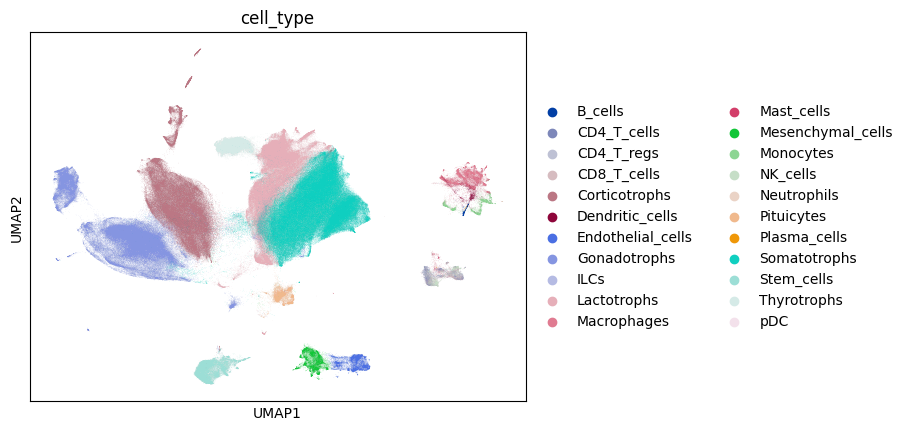

In [ ]:
sc.pl.umap(adata,color="cell_type")

In [ ]:
#make plot of all cells
adata.obs["Author"].nunique()

14

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

sc.pl.umap(
    adata,
    color="cell_type",
    show=False
)

plt.savefig(
    "umap_final_cell_type_specific.png",
    dpi=600,
    bbox_inches="tight"
)
plt.close()


In [ ]:
import io
import pandas as pd

to_keep = metadata["SRA_ID"].values

adata_subset = adata[adata.obs["SRA_ID"].isin(to_keep)].copy()

In [ ]:
adata_subset.layers["counts"] = adata_subset.X.copy()

In [ ]:
sc.pp.normalize_total(adata_subset, target_sum=1e4)
sc.pp.log1p(adata_subset)

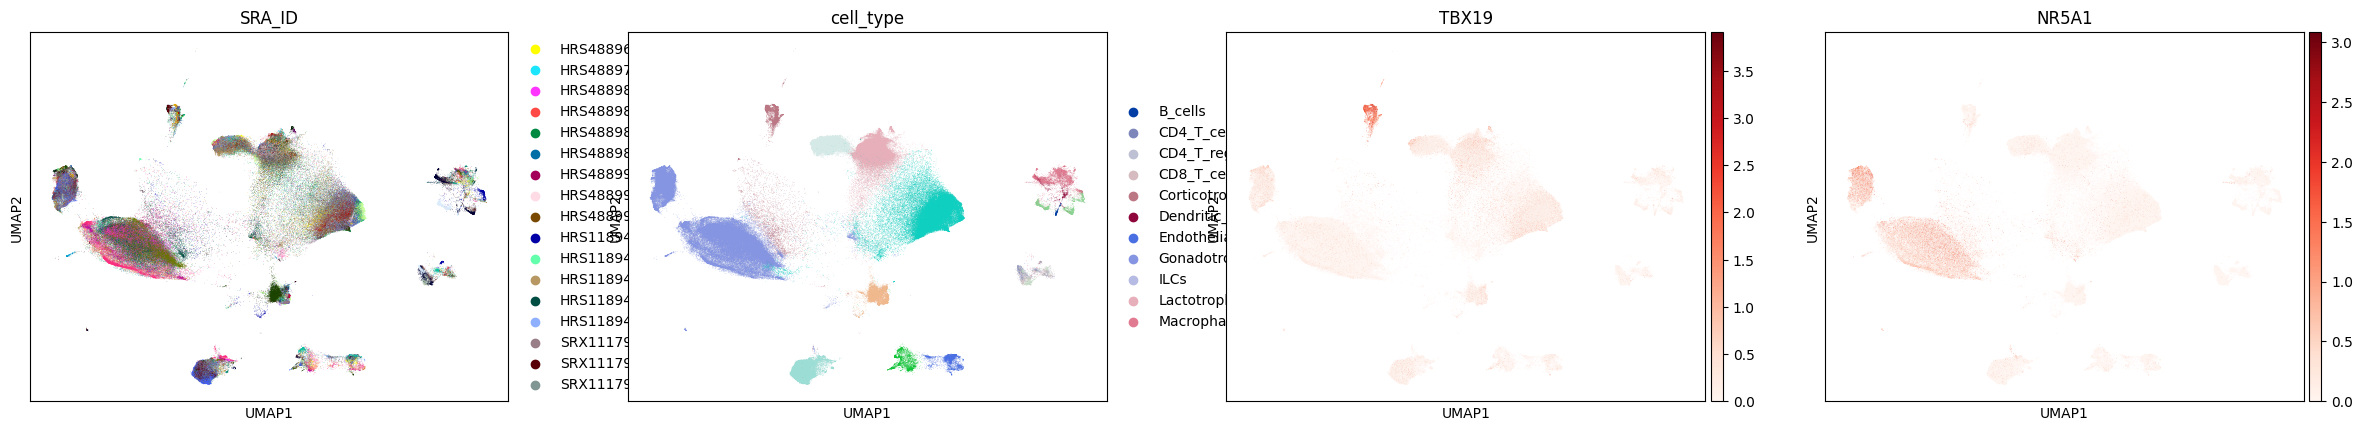

In [ ]:
sc.pl.umap(adata_subset, color=["SRA_ID","cell_type","TBX19","NR5A1"], cmap="Reds", sort_order=False)

In [ ]:
#crosstab
pd.crosstab(adata_subset.obs["SRA_ID"], adata_subset.obs["cell_type"])

cell_type,B_cells,CD4_T_cells,CD4_T_regs,CD8_T_cells,Corticotrophs,Dendritic_cells,Endothelial_cells,Gonadotrophs,ILCs,Lactotrophs,...,Mesenchymal_cells,Monocytes,NK_cells,Neutrophils,Pituicytes,Plasma_cells,Somatotrophs,Stem_cells,Thyrotrophs,pDC
SRA_ID,,,,,,,,,,,,,,,,,,,,,
HRS488968,0,8,2,12,33,33,207,29,0,39,...,143,9,7,0,0,0,362,43,140,0
HRS488978,0,10,2,22,3,9,32,39,0,127,...,8,15,25,0,0,0,87,33,85,0
HRS488982,0,0,0,0,220,1,9,3333,0,6,...,4,0,0,0,0,0,29,153,0,0
HRS488984,0,0,0,0,117,1,5,4001,0,7,...,1,0,0,0,0,0,56,4,0,0
HRS488986,0,0,0,0,41,1,0,5751,0,6,...,1,1,0,0,0,0,75,3,10,0
HRS488987,0,0,0,0,9,8,0,241,0,1,...,0,3,0,0,0,0,1,1,0,0
HRS488990,0,0,0,0,366,1,0,1979,0,53,...,1,0,0,0,0,0,218,300,4,0
HRS488996,1,3,1,0,8,11,2,111,0,1868,...,10,6,0,0,0,0,579,95,186,3
HRS488997,0,0,0,1,2,7,43,65,0,174,...,15,12,0,0,0,0,66,55,289,0


# Removing samples with annotations that disagree with gonadotroph NFPA origin

In [ ]:
#remove HRS1189473
adata_subset = adata_subset[~adata_subset.obs["SRA_ID"].isin(["HRS1189473"])].copy()

In [ ]:
#adata_subset = adata_subset[~adata_subset.obs["final_cell_type_specific"].isin(["Lactotroph_tumor","POU1F1_multihormonal_tumor","Thyrotroph_tumor","Somatotroph_tumor","Silent_corticotroph_tumor","Corticotroph_tumor","Gonadotroph_tumor"])].copy()

In [ ]:
#crosstab
pd.crosstab(adata_subset.obs["SRA_ID"], adata_subset.obs["cell_type"])

cell_type,B_cells,CD4_T_cells,CD4_T_regs,CD8_T_cells,Corticotrophs,Dendritic_cells,Endothelial_cells,Gonadotrophs,ILCs,Lactotrophs,...,Mesenchymal_cells,Monocytes,NK_cells,Neutrophils,Pituicytes,Plasma_cells,Somatotrophs,Stem_cells,Thyrotrophs,pDC
SRA_ID,,,,,,,,,,,,,,,,,,,,,
HRS488968,0,8,2,12,33,33,207,29,0,39,...,143,9,7,0,0,0,362,43,140,0
HRS488978,0,10,2,22,3,9,32,39,0,127,...,8,15,25,0,0,0,87,33,85,0
HRS488982,0,0,0,0,220,1,9,3333,0,6,...,4,0,0,0,0,0,29,153,0,0
HRS488984,0,0,0,0,117,1,5,4001,0,7,...,1,0,0,0,0,0,56,4,0,0
HRS488986,0,0,0,0,41,1,0,5751,0,6,...,1,1,0,0,0,0,75,3,10,0
HRS488987,0,0,0,0,9,8,0,241,0,1,...,0,3,0,0,0,0,1,1,0,0
HRS488990,0,0,0,0,366,1,0,1979,0,53,...,1,0,0,0,0,0,218,300,4,0
HRS488996,1,3,1,0,8,11,2,111,0,1868,...,10,6,0,0,0,0,579,95,186,3
HRS488997,0,0,0,1,2,7,43,65,0,174,...,15,12,0,0,0,0,66,55,289,0


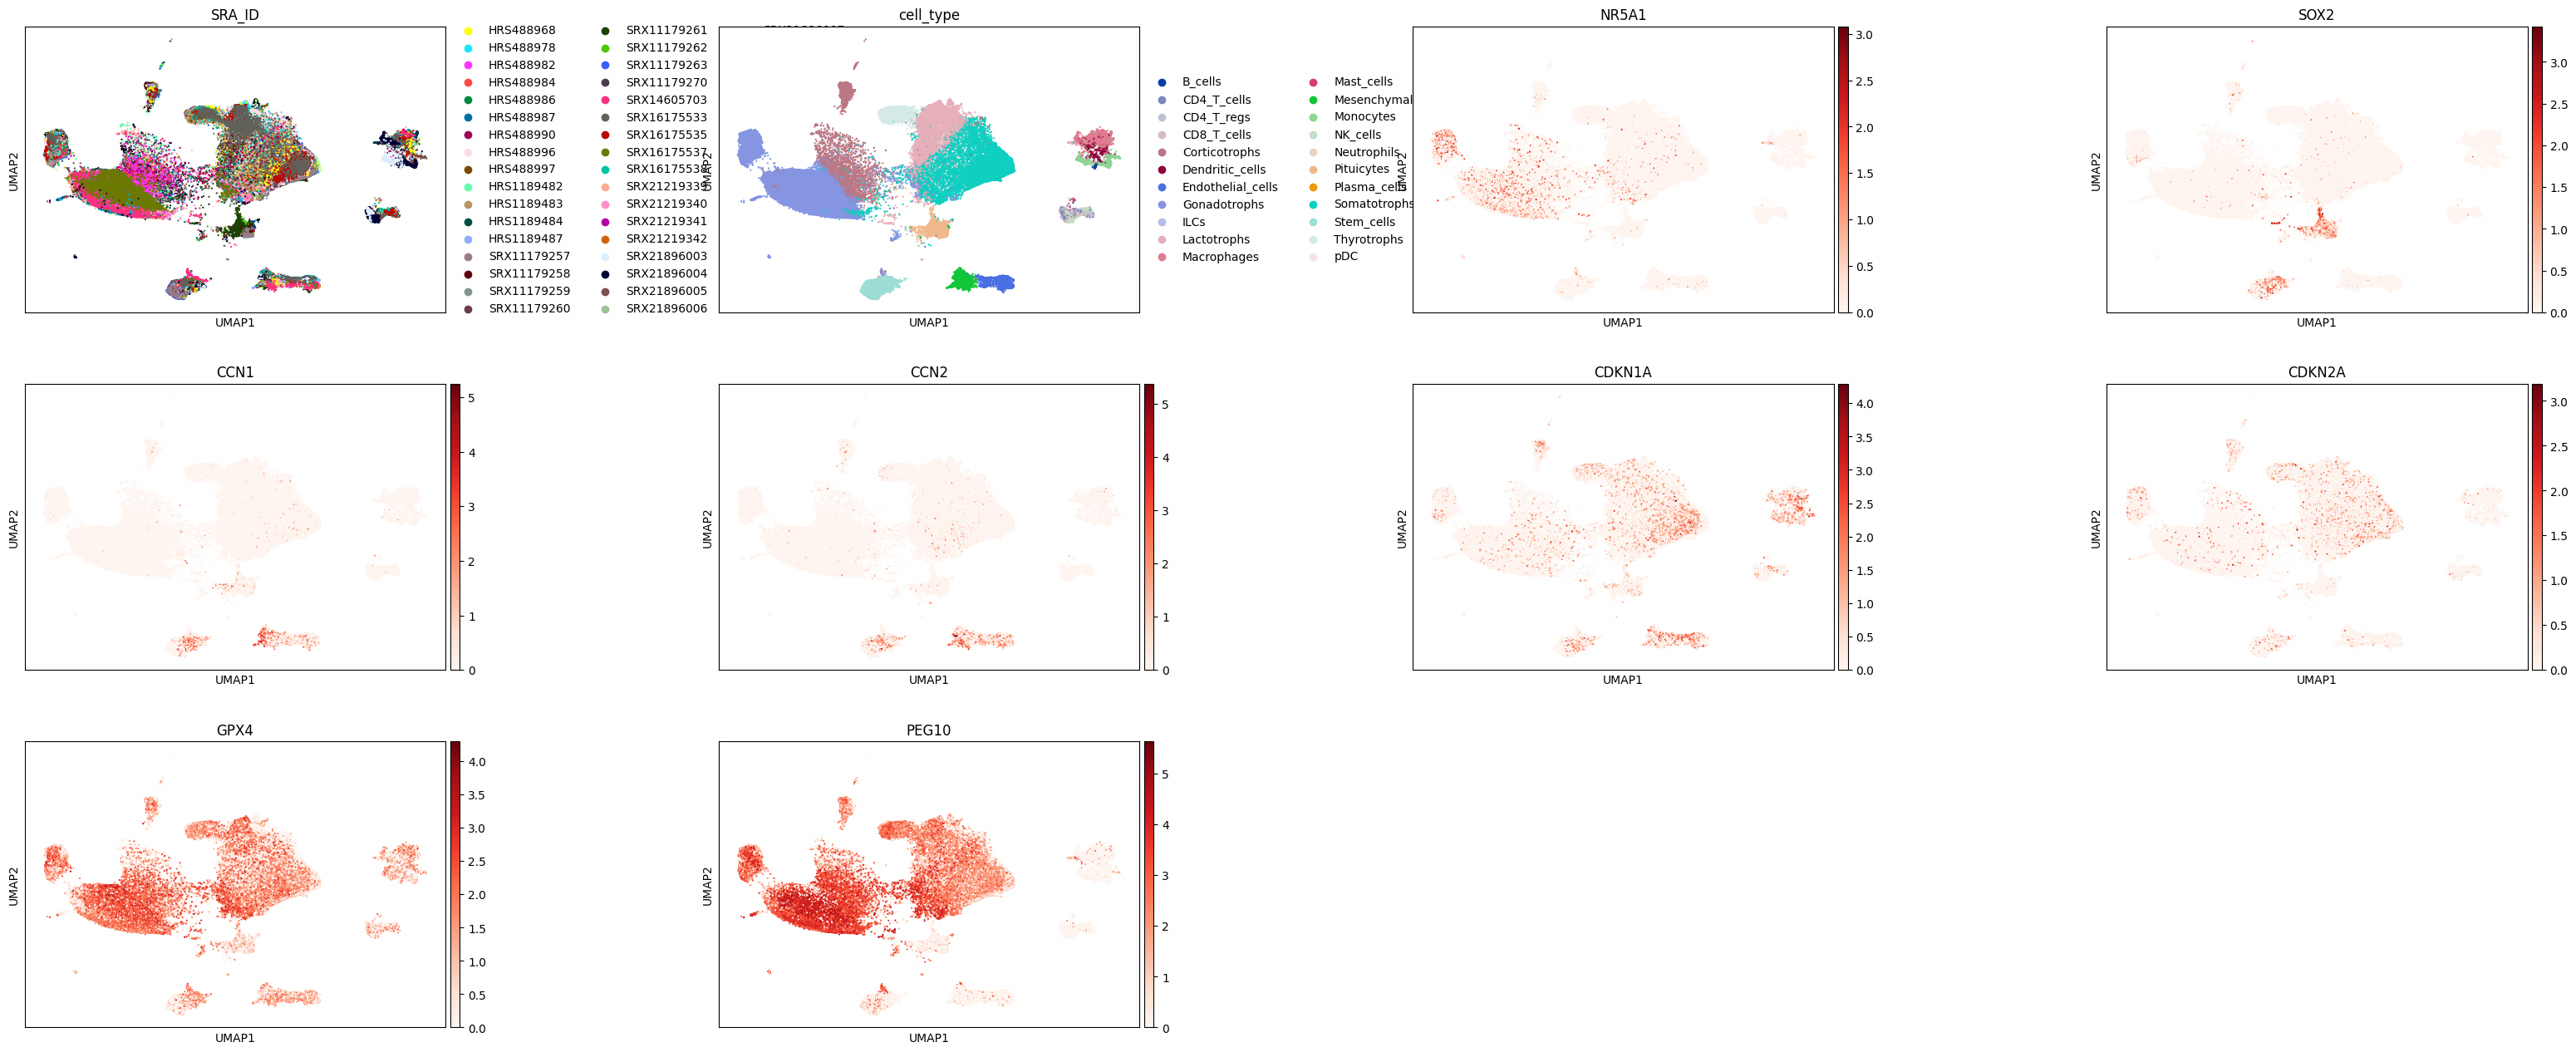

In [ ]:
sc.pl.umap(adata_subset, color=["SRA_ID","cell_type","NR5A1","SOX2","CCN1","CCN2","CDKN1A","CDKN2A","GPX4","PEG10"], s=10, cmap="Reds", sort_order=False, wspace=0.5)

# Saving object to drive

In [ ]:
#write out for seurat
adata_subset.write(f"/content/drive/MyDrive/nfpa_handover/merged_object_2026_10_27.h5ad", compression="gzip")

# Pseudobulk

In [ ]:
import decoupler as dc

In [ ]:
import pandas as pd
import numpy as np

# Add Series.nonzero if missing
if not hasattr(pd.Series, "nonzero"):
    pd.Series.nonzero = lambda self: np.asarray(self).nonzero()

In [ ]:
import scanpy as sc
adata_subset = sc.read(f"/content/drive/MyDrive/nfpa_handover/merged_object_2026_10_27.h5ad")
adata_subset

AnnData object with n_obs × n_vars = 104321 × 39074
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'assay', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'Internal_ID', 'Name', 'Normal', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'KNOSP', 'KI67', 'Invasion', 'USP8_geno', 'USP48_geno', 'BRAF_geno', 'Pool', '10X version', 'Modality', 'pseudoaligned', 'Core', 'passed_qc', 'filtering_junk', 'n_cells', 'pct_counts_in_top_20_genes', 'SRA_barcode', 'cell_type', 'leiden_scVI', 'leiden_scVI_final', 'final_cell_type_broad', 'final_cell_type_specific'
    var: 'mt', 'ribo', 'malat', 'n_cells_by_counts', 'mean

In [ ]:
adata_subset

AnnData object with n_obs × n_vars = 285907 × 39074
    obs: 'Internal_ID', 'GEO', 'SRA_ID', 'Name', 'Normal', 'DOI', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'Other disease', 'Treatment', 'Response_Short', 'Response_Long', 'Primary_recurrent', 'KNOSP', 'KI67', 'KI67_pta', 'Invasion', 'USP8_geno', 'TP53_geno', 'GNAS_geno', 'USP48_geno', 'BRAF_geno', 'Pool', 'Modality', 'Final_sex', 'cell_type', 'cell_barcode', 'SRA_barcode'
    uns: 'cell_type_colors', 'log1p', 'SRA_ID_colors'
    obsm: 'X_umap'
    layers: None (.X), 'counts'

In [ ]:
pdata = dc.pp.pseudobulk(
    adata_subset,
    sample_col="SRA_ID",
    groups_col="cell_type",
    mode="sum",
    layer="counts"
)

In [ ]:
#remove where less than min_cells
min_cells = 25


In [ ]:
pdata = pdata[pdata.obs["psbulk_cells"] >= min_cells]
pdata

View of AnnData object with n_obs × n_vars = 370 × 39074
    obs: 'SRA_ID', 'cell_type', 'Internal_ID', 'GEO', 'Name', 'Normal', 'DOI', 'Author', 'Tumor_pta', 'Age_numeric', 'Sex_numeric', 'Sex', 'Ethnicity', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'Other disease', 'Treatment', 'Response_Short', 'Response_Long', 'Primary_recurrent', 'KNOSP', 'KI67', 'KI67_pta', 'Invasion', 'USP8_geno', 'TP53_geno', 'GNAS_geno', 'USP48_geno', 'BRAF_geno', 'Pool', 'Modality', 'Final_sex', 'psbulk_cells', 'psbulk_counts'
    layers: 'psbulk_props', None (.X)

In [ ]:
pdata.obs = pdata.obs.astype(str)
pdata.var = pdata.var.astype(str)

In [ ]:
#write
pdata.write("/content/drive/MyDrive/nfpa_handover/nfpa_pseudobulk_2026_10_27.h5ad")

In [ ]:
pip freeze

absl-py==2.0.0
accelerate==1.15.0
access==1.1.10.post3
adjustText==1.4.0
affine==3.0.1
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.5
aiosignal==1.4.0
aiosqlite==0.22.1
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.12.1
altair==5.5.0
anndata==0.13.4
annotated-doc==0.0.5
annotated-types==0.8.0
anyio==4.15.1
anywidget==0.9.21
apsw==3.54.1.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
array-api-compat==1.16.0
array_record==0.8.6
arrow==1.4.0
arviz==0.22.0
astropy==7.2.3
astropy-iers-data==0.2026.10.19.0.52.1
astunparse==1.6.3
atpublic==5.1
attrs==26.1.0
audioop-lts==0.2.2
audioread==3.1.0
Authlib==1.9.1
autograd==1.9.1
babel==2.18.0
backcall==0.2.0
beartype==0.23.1
beautifulsoup4==4.13.5
betterproto==2.0.0b7
bigframes==2.51.0
bigquery-magics==0.14.0
bleach==6.4.0
blinker==1.9.0
blis==1.3.3
blobfile==3.3.0
blosc2==4.14.1
bokeh==3.8.2
Bottleneck==1.4.2
bqplot==0.12.47
branca==0.8.2
brotli==1.2.0
CacheControl==0.14.4
cachetools==6.2.6
catalogue==2.0.10
cert